In [7]:
from sklearn.preprocessing import LabelEncoder

def fillna(df):
    df["Age"].fillna(df["Age"].mean(), inplace = True)
    df["Cabin"].fillna("N", inplace = True)
    df["Embarked"].fillna("N", inplace = True)
    df["Fare"].fillna(0, inplace = True)
    return df

def drop_features(df):
    df.drop(["PassengerId", "Name", "Ticket"], axis = 1, inplace = True)
    return df

def format_features(df):
    df["Cabin"] = df["Cabin"].str[:1]
    features = ["Cabin", "Sex", "Embarked"]
    for feature in features:
        le = LabelEncoder()
        le = le.fit(df[feature])
        df[feature] = le.transform(df[feature])
    return df

def transform_features(df):
    df = fillna(df)
    df = drop_features(df)
    df = format_features(df)
    return df

In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("./train.csv")
y_df = df["Survived"]
X_df = df.drop("Survived", axis = 1)
X_df = transform_features(X_df)

X_train, X_test, y_train, y_test = train_test_split(X_df, y_df,
                        test_size = 0.2, random_state = 42)

In [10]:
import numpy as np
from sklearn.linear_model import LogisticRegression

lr_clf = LogisticRegression(solver = "liblinear")

lr_clf.fit(X_train, y_train)
pred = lr_clf.predict(X_test)

In [13]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import confusion_matrix

confusion = confusion_matrix(y_test, pred)
accuracy = accuracy_score(y_test, pred)
precision = precision_score(y_test, pred)
recall = recall_score(y_test, pred)

print(confusion)
print()
print(accuracy)
print(precision)
print(recall)

[[90 15]
 [22 52]]

0.7932960893854749
0.7761194029850746
0.7027027027027027


In [15]:
pred_proba = lr_clf.predict_proba(X_test)

print("pred_proba() 결과 shape :", pred_proba.shape)
print("pred_proba array 앞 3개의 샘플 :", pred_proba[:3])

pred_proba_result = np.concatenate([pred_proba, pred.reshape(-1, 1)], axis = 1)
print("두 개의 클래스 중에서 더 큰 확률을 클래스 값으로 예측 :", pred_proba_result[:3])


pred_proba() 결과 shape : (179, 2)
pred_proba array 앞 3개의 샘플 : [[0.88321001 0.11678999]
 [0.79410275 0.20589725]
 [0.85187919 0.14812081]]
두 개의 클래스 중에서 더 큰 확률을 클래스 값으로 예측 : [[0.88321001 0.11678999 0.        ]
 [0.79410275 0.20589725 0.        ]
 [0.85187919 0.14812081 0.        ]]


In [16]:
from sklearn.preprocessing import Binarizer

X = [[1, -1, 2],
     [2, 0, 0],
     [0, 1.1, 1.2]]
binarizer = Binarizer(threshold=1.1)
print(binarizer.fit_transform(X))

[[0. 0. 1.]
 [1. 0. 0.]
 [0. 0. 1.]]


In [18]:
custom_threshold = 0.6

pred_proba_1 = pred_proba[:, 1].reshape(-1, 1)
binarizer = Binarizer(threshold=custom_threshold).fit(pred_proba_1)
custom_pred = binarizer.transform(pred_proba_1)

confusion = confusion_matrix(y_test, custom_pred)
accuracy = accuracy_score(y_test, custom_pred)
precision = precision_score(y_test, custom_pred)
recall = recall_score(y_test, custom_pred)

print(confusion)
print()
print(accuracy)
print(precision)
print(recall)

[[94 11]
 [24 50]]

0.8044692737430168
0.819672131147541
0.6756756756756757


In [20]:
from sklearn.metrics import precision_recall_curve

pred_proba_class1 = lr_clf.predict_proba(X_test)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_test,
                                                         pred_proba_class1)
print("반환된 분류 결정 임계값 배열의 모양 :", thresholds.shape)
print("반환된 분류 결정 정밀도 배열의 모양 :", precisions.shape)
print("반환된 분류 결정 재현율 배열의 모양 :", recalls.shape)
print()

print("Thresholds 5 sample :", thresholds[:5])
print("precisions 5 sample :", precisions[:5])
print("recalls 5 sample :", recalls[:5])
print()

thr_index = np.arange(0, thresholds.shape[0], 15)
print("샘플 추출을 위한 임계값 배열의 인덱스 10개 :", thr_index)
print("샘플용 10개의 임계값 :", np.round(thresholds[thr_index], 2))
print()

print("샘플 임계값별 정밀도 :", np.round(precisions[thr_index], 3))
print("샘플 임계값별 재현율 :", np.round(recalls[thr_index], 3))

반환된 분류 결정 임계값 배열의 모양 : (168,)
반환된 분류 결정 정밀도 배열의 모양 : (169,)
반환된 분류 결정 재현율 배열의 모양 : (169,)

Thresholds 5 sample : [0.0937931  0.09557377 0.09738461 0.09826648 0.09901517]
precisions 5 sample : [0.42774566 0.4244186  0.42690058 0.42941176 0.43195266]
recalls 5 sample : [1.         0.98648649 0.98648649 0.98648649 0.98648649]

샘플 추출을 위한 임계값 배열의 인덱스 10개 : [  0  15  30  45  60  75  90 105 120 135 150 165]
샘플용 10개의 임계값 : [0.09 0.12 0.14 0.15 0.2  0.29 0.36 0.57 0.66 0.73 0.87 0.93]

샘플 임계값별 정밀도 : [0.428 0.452 0.504 0.565 0.615 0.691 0.734 0.797 0.917 1.    1.    1.   ]
샘플 임계값별 재현율 : [1.    0.959 0.946 0.946 0.905 0.878 0.784 0.689 0.595 0.446 0.243 0.041]


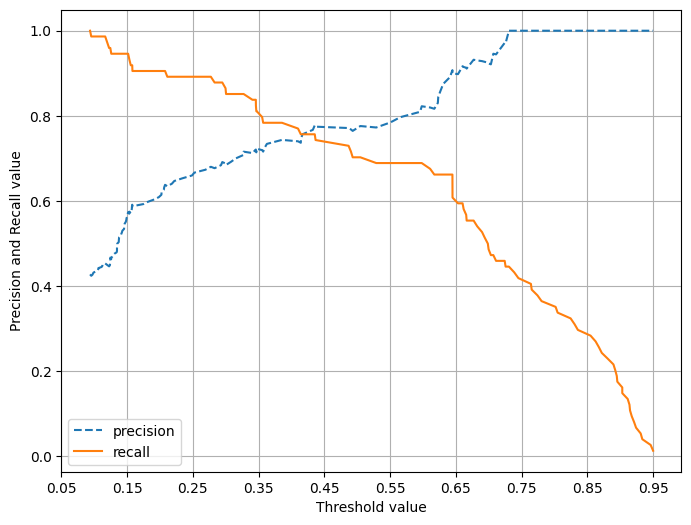

In [21]:
import matplotlib.pyplot as plt

def precision_recall_curve_plot(y_test, pred_proba_c1):
    precisions, recalls, thresholds = precision_recall_curve(y_test,
                                                             pred_proba_c1)
    plt.figure(figsize=(8, 6))
    threshold_boundary = thresholds.shape[0]
    plt.plot(thresholds, precisions[0:threshold_boundary],
             linestyle = "--", label = "precision")
    plt.plot(thresholds, recalls[0:threshold_boundary],
             label = "recall")
    start, end = plt.xlim()
    plt.xticks(np.round(np.arange(start, end, 0.1), 2))
    plt.xlabel("Threshold value")
    plt.ylabel("Precision and Recall value")
    plt.legend()
    plt.grid()
    plt.show()

precision_recall_curve_plot(y_test, lr_clf.predict_proba(X_test)[:, 1])

In [22]:
from sklearn.metrics import f1_score

f1 = f1_score(y_test, pred)
print(f1)

0.7375886524822697


In [ ]:
from sklearn.metrics import roc_curve

pred_proba_class1 = lr_clf.predict_proba(X_test)[:, 1]

# FPR = 1 - 특이도
# TPR = Recall
fprs, tprs, thresholds = roc_curve(y_test, pred_proba_class1)
thr_index = np.arange(1, thresholds.shape[0], 5)
print(np.round(fprs[thr_index], 3))
print(np.round(tprs[thr_index], 3))

[0.    0.019 0.048 0.143 0.19  0.238 0.295 0.486 0.695 0.838]
[0.014 0.473 0.595 0.689 0.784 0.838 0.892 0.919 0.946 0.986]


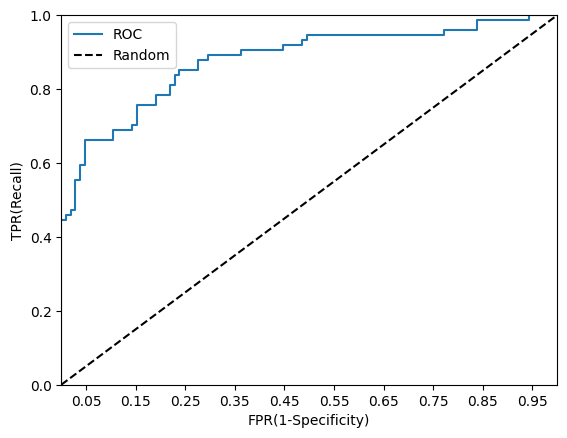

In [24]:
def roc_curve_plot(y_test, pred_proba_c1):
    fprs, tprs, thresholds = roc_curve(y_test, pred_proba_c1)
    plt.plot(fprs, tprs, label = "ROC")
    plt.plot([0, 1], [0, 1], "k--", label = "Random")
    start, end = plt.xlim()
    plt.xticks(np.round(np.arange(start, end, 0.1), 2))
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.xlabel("FPR(1-Specificity)")
    plt.ylabel("TPR(Recall)")
    plt.legend()
    plt.show()

roc_curve_plot(y_test, lr_clf.predict_proba(X_test)[:, 1])

In [26]:
from sklearn.metrics import roc_auc_score

roc_score = roc_auc_score(y_test, lr_clf.predict_proba(X_test)[:, 1])
print(roc_score)

0.8776061776061777


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [28]:
df = pd.read_csv("./diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
def get_clf_eval(y_test, pred = None, pred_proba = None):
    confusion = confusion_matrix(y_test, pred)
    accuracy = accuracy_score(y_test, pred)
    precision = precision_score(y_test, pred)
    recall = recall_score(y_test, pred)
    f1 = f1_score(y_test, pred)
    roc_auc = roc_auc_score(y_test, pred_proba)
    print("오차행렬")
    print(confusion)
    print("정확도 :", accuracy)
    print("정밀도 :", precision)
    print("재현율 :", recall)
    print("f1 :", f1)
    print("roc_auc :", roc_auc)

In [32]:
df["Outcome"].value_counts()

0    500
1    268
Name: Outcome, dtype: int64

In [33]:
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2,
                                                    random_state = 42,
                                                    stratify = y)

In [34]:
lr_clf = LogisticRegression(solver = "liblinear")
lr_clf.fit(X_train, y_train)
pred = lr_clf.predict(X_test)
pred_proba = lr_clf.predict_proba(X_test)[:, 1]

get_clf_eval(y_test, pred, pred_proba)

오차행렬
[[85 15]
 [27 27]]
정확도 : 0.7272727272727273
정밀도 : 0.6428571428571429
재현율 : 0.5
f1 : 0.5625000000000001
roc_auc : 0.8285185185185185


In [35]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


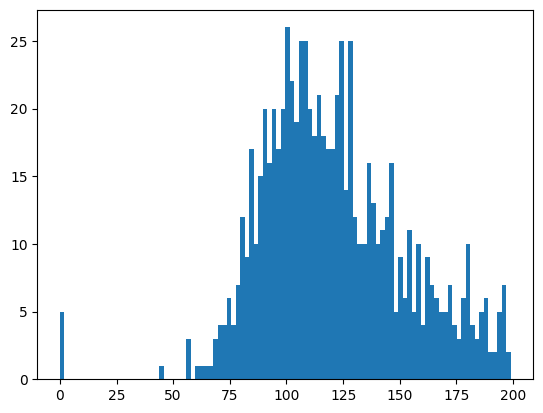

In [36]:
plt.hist(df["Glucose"], bins = 100)
plt.show()

In [39]:
zero_features = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

total_count = df["Glucose"].count()

for feature in zero_features:
    zero_count = df[df[feature] == 0][feature].count()
    print(feature, zero_count, 100 * zero_count / total_count)

Glucose 5 0.6510416666666666
BloodPressure 35 4.557291666666667
SkinThickness 227 29.557291666666668
Insulin 374 48.697916666666664
BMI 11 1.4322916666666667


In [41]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# fit 또는 fit_transform은 딱 한버만 쓸 수 있음 : 재학습의 경우 재사용 가능
# X_train에 fit 했으면, X_test는 무조건 transform만 해야 함
X_train, X_test, y_train, y_test = train_test_split(X_scaled, 
            y, test_size = 0.2, random_state = 42, stratify = y)

# 스케일링한 후에 모델 재학습
lr_clf.fit(X_train, y_train)
pred = lr_clf.predict(X_test)
pred_proba = lr_clf.predict_proba(X_test)[:, 1]

get_clf_eval(y_test, pred, pred_proba)

오차행렬
[[82 18]
 [26 28]]
정확도 : 0.7142857142857143
정밀도 : 0.6086956521739131
재현율 : 0.5185185185185185
f1 : 0.5599999999999999
roc_auc : 0.8229629629629629
